## Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

## Load Libraries

In [3]:
library(tidyr)
library(dplyr)
library(ggplot2)
library(tibble)
library(patchwork)

# Load Metadata

In [28]:
# Read in metadata
metadata <- read.csv("metadata.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$Gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ MECP2:'data.frame':	32 obs. of  23 variables:
  ..$ Gene                      : chr [1:32] "MECP2" "MECP2" "MECP2" "MECP2" ...
  ..$ Sample_ID                 : chr [1:32] "KB1" "KB2" "KB3" "KB19" ...
  ..$ Sample_Name               : chr [1:32] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3" "CO_R270X_B2_d18_A1" ...
  ..$ Cell_Type                 : chr [1:32] "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" ...
  ..$ Genotype                  : chr [1:32] "MUT" "MUT" "MUT" "MUT" ...
  ..$ Time_Point                : chr [1:32] "D18" "D18" "D18" "D18" ...
  ..$ Group                     : chr [1:32] "R270X_D18" "R270X_D18" "R270X_D18" "R270X_D18" ...
  ..$ Replicate                 : int [1:32] 1 2 3 4 5 6 1 2 3 4 ...
  ..$ Clean_Sample_Name         : chr [1:32] "R270X_D18_1" "R270X_D18_2" "R270X_D18_3" "R270X_D18_4" ...
  ..$ Batch                     : int [1:32] 0 0 0 1 1 1 0 0 0 1 ...
  ..$ D18_MUT_vs_D18_WT         : int 

In [29]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$Group))
}


=== Group counts for MECP2 ===

R270X_D18 R270X_D46 R270X_D90    WT_D18    WT_D46    WT_D90 
        6         4         6         6         5         5 


# Load Counts

In [30]:
# Read in counts
counts <- read.delim("05_gene_counts/MECP2_normalized_counts.txt")

# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata.csv")[, c("Sample_Name", "Clean_Sample_Name")]

# Create mapping
name_mapping <- setNames(mapping_df$Clean_Sample_Name, mapping_df$Sample_Name)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# View
head(counts)

,R270X_D18_1,R270X_D18_2,R270X_D18_3,R270X_D18_4,R270X_D18_5,R270X_D18_6,R270X_D46_1,R270X_D46_2,R270X_D46_3,R270X_D46_4,⋯,WT_D46_1,WT_D46_2,WT_D46_3,WT_D46_4,WT_D46_5,WT_D90_1,WT_D90_2,WT_D90_3,WT_D90_4,WT_D90_5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A0A024R0Q4,1.5955131,1.776155,1.051596,1.325690,1.876562,1.2972164,1.441147,1.793023,1.9981165,1.997648,⋯,2.0175780,2.258242,1.785696,1.764698,0.45101005,1.779600,2.520144,1.991368,2.835845,1.990374
A0A024R5G2,6.5338210,6.600780,6.693552,6.926624,6.770172,7.3023333,6.433098,6.170686,6.3606658,6.624274,⋯,6.2838073,6.174269,6.288047,6.365530,7.34696247,5.865562,5.584527,6.156353,5.753729,5.910733
A0A024RAA5,1.0213060,1.776155,1.051596,2.429266,2.176069,0.6618769,2.887948,2.543490,3.4020222,2.988700,⋯,3.3312998,3.147539,3.043483,2.958170,2.22289674,2.911341,3.428417,2.981747,2.097798,1.990374
A0A024RAJ1,0.4523278,1.148576,1.271631,2.222271,1.263736,2.7728478,1.441147,0.917640,1.7066873,1.232729,⋯,0.7735121,1.685210,1.922383,0.060944,-0.50075523,2.622903,2.520144,1.867580,1.095090,1.009635
A0A024RBW1,4.0801219,4.367480,4.006765,4.252824,3.325689,2.9467234,1.032681,1.618853,0.8502006,1.873739,⋯,1.0311523,1.537162,1.274966,2.524291,0.05223064,2.361044,1.252954,1.732164,2.097798,1.415074
A0A024RDL5,3.2182169,2.878073,3.360271,3.382059,3.699480,3.8790375,4.401071,4.862035,4.1892690,4.305232,⋯,4.0945736,4.635590,4.011270,3.955019,4.61330215,3.095188,3.184200,2.920766,4.129587,4.880361


# Subset to Genes of Interest

In [31]:
# Load genes of interest
genes_of_interest <- read.csv("azimuth_2023_cell_type_markers.csv")

genes_of_interest <- genes_of_interest %>%
  mutate(Gene_List = strsplit(Gene_List, "|", fixed = TRUE)) %>%
  deframe()

# View
str(genes_of_interest)

List of 7
 $ Glutamatergic Neuron             : chr [1:9] "SATB2" "CELF2" "PHACTR1" "CHN1" ...
 $ GABAergic Neuron                 : chr [1:9] "GRIP1" "KAZN" "KCNC2" "TCF4" ...
 $ Non-neuronal Cell                : chr [1:9] "ZBTB20" "NCKAP5" "PTGDS" "PHLPP1" ...
 $ Astrocyte                        : chr [1:9] "ADGRV1" "SLC1A3" "GPC5" "RNF219.AS1" ...
 $ Microglia/Perivascular Macrophage: chr [1:9] "P2RY12" "APBB1IP" "FYB" "PTPRC" ...
 $ Oligodendrocyte                  : chr [1:9] "ST18" "CTNNA3" "MBP" "MOBP" ...
 $ Oligodendrocyte Precursor Cell   : chr [1:9] "PDGFRA" "OLIG1" "SMOC1" "COL9A1" ...


In [32]:
# Select only genes of interest
all_target_genes <- unlist(genes_of_interest, use.names = FALSE)

counts <- counts[rownames(counts) %in% all_target_genes, ]

# View
head(counts)

,R270X_D18_1,R270X_D18_2,R270X_D18_3,R270X_D18_4,R270X_D18_5,R270X_D18_6,R270X_D46_1,R270X_D46_2,R270X_D46_3,R270X_D46_4,⋯,WT_D46_1,WT_D46_2,WT_D46_3,WT_D46_4,WT_D46_5,WT_D90_1,WT_D90_2,WT_D90_3,WT_D90_4,WT_D90_5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ADGRV1,2.416111,2.469735,1.9185499,0.09314743,1.263736,2.216005,2.7511693,2.8098798,2.8644983,2.98869980,⋯,3.7449650,3.095551,2.9822455,4.1035727,3.6917074,1.04964702,2.52014383,1.227395,1.8342225,1.86660494
CHN1,2.805515,2.303148,2.0433271,2.22227147,2.730584,1.533685,2.8211791,1.1910054,3.2986867,2.49489155,⋯,2.8858345,2.160417,2.3676621,1.6142935,2.0028962,2.04087603,1.76095329,1.010420,1.9720213,1.00963536
COL9A1,4.849043,4.950049,4.8606157,3.65367376,3.130153,3.173617,0.0586744,-0.5007552,0.8502006,1.23272884,⋯,0.4596376,0.415781,0.7946472,-0.5007552,0.7630946,0.47340251,0.46190311,1.867580,-0.5007552,0.04740308
ENPP2,2.735592,3.374636,3.4074691,1.68994462,2.635437,2.575108,1.4411469,1.7930235,1.1164245,0.05020433,⋯,1.4394186,1.372166,2.3676621,0.0609440,0.7630946,0.06703063,0.05942053,1.415963,1.3182568,1.41507439
KALRN,1.595513,1.776155,-0.5007552,0.51263432,1.498135,1.297216,2.5181098,3.0346642,3.2441039,2.11175246,⋯,3.0107426,2.055473,2.6296964,1.0372995,1.4262741,0.79010614,2.24198098,1.732164,2.5135118,1.99037414
KAZN,4.108062,3.642286,3.7744759,4.65442896,3.957264,3.879038,2.6775882,2.8887640,4.1302965,3.72207038,⋯,2.5160615,2.985592,3.2653387,3.5617309,3.3618400,3.40470760,3.74937683,4.273690,2.5135118,3.20164358


# Make Expression Box Plot

In [33]:
# Reshape data 
counts_long <- counts %>%
  rownames_to_column(var = "gene") %>%
  pivot_longer(
    cols = -gene,         
    names_to = "sample",   
    values_to = "expression"
  ) %>%
  mutate(
    group = gsub("_\\d+$", "", sample),
    date = gsub(".*_", "", group)
  )

# View
head(counts_long)

gene,sample,expression,group,date
<chr>,<chr>,<dbl>,<chr>,<chr>
ADGRV1,R270X_D18_1,2.41611082,R270X_D18,D18
ADGRV1,R270X_D18_2,2.46973475,R270X_D18,D18
ADGRV1,R270X_D18_3,1.91854991,R270X_D18,D18
ADGRV1,R270X_D18_4,0.09314743,R270X_D18,D18
ADGRV1,R270X_D18_5,1.26373550,R270X_D18,D18
ADGRV1,R270X_D18_6,2.21600462,R270X_D18,D18


In [34]:
# Convert date to factor with desired order
counts_long$date <- factor(counts_long$date, levels = c("D18", "D46", "D90"))

# Sort by date, then genotype
counts_long$genotype <- gsub("_.*", "", counts_long$group)

# Create ordered factor
counts_long$group_ordered <- factor(counts_long$group, 
                                     levels = c("WT_D18", "R270X_D18", 
                                                "WT_D46", "R270X_D46",
                                                "WT_D90", "R270X_D90"))

# Replace underscores with spaces for plot labeling
levels(counts_long$group_ordered) <- gsub("_", " ", levels(counts_long$group_ordered))

# Replace R270X with MUT
levels(counts_long$group_ordered) <- gsub("R270X", "MUT", levels(counts_long$group_ordered))

In [35]:
# Create a data frame mapping each gene to its cell type
gene_celltype_map <- data.frame(
  gene = unlist(genes_of_interest, use.names = FALSE),
  cell_type = rep(names(genes_of_interest), lengths(genes_of_interest))
)

# Merge the mapping with long counts data
counts_long_mapped <- counts_long %>%
  left_join(gene_celltype_map, by = "gene") %>%
  filter(!is.na(cell_type)) 

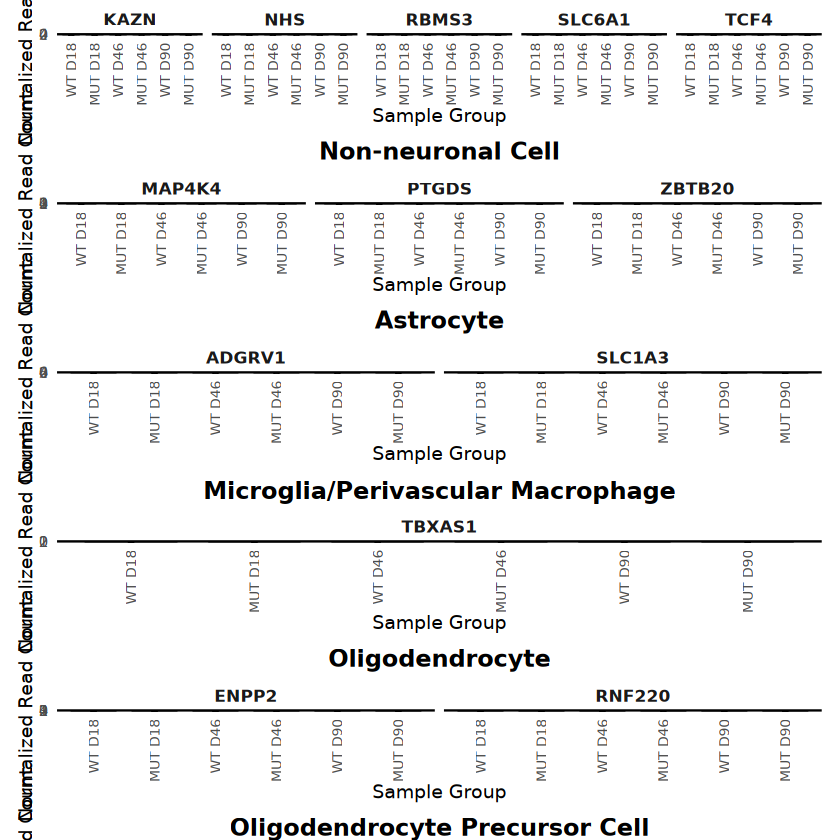

In [50]:
library(dplyr)
library(ggplot2)
library(patchwork)

# Remove rows where the gene was not found in the counts data (NAs)
counts_long_clean <- counts_long_mapped %>%
  filter(!is.na(expression))

# Create a list to store plots for each cell type
celltype_plots <- list()

# Loop through each cell type
for (ct in names(genes_of_interest)) {
  
  # Subset data for this cell type
  ct_data <- counts_long_clean %>%
    filter(cell_type == ct)
  
  # Skip if no data
  if (nrow(ct_data) == 0) next
  
  # Get the genes for this cell type that actually have data
  ct_genes <- unique(ct_data$gene)
  
  # Order genes according to the original list
  ct_genes <- ct_genes[ct_genes %in% genes_of_interest[[ct]]]
  ct_genes <- factor(ct_genes, levels = genes_of_interest[[ct]][genes_of_interest[[ct]] %in% ct_genes])
  
  # Create a plot for this cell type with all its genes
  p <- ggplot(ct_data, aes(x = group_ordered, y = expression, fill = date)) +
    geom_boxplot(outlier.shape = NA) +
    geom_jitter(width = 0, alpha = 1, size = 0.8) +
    
    # Facet by gene within this cell type
    facet_wrap(~ gene, ncol = length(ct_genes), scales = "free_x") +
    
    theme_minimal() +
    theme(
      axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 8),
      plot.title = element_text(hjust = 0.5, face = "bold", size = 14),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank(),
      axis.line = element_line(color = "black"),
      legend.position = "none",
      strip.text = element_text(face = "bold", size = 10)
    ) +
    labs(title = ct, 
         x = "Sample Group", 
         y = "Normalized Read Count", 
         fill = "Time Point") +
    scale_fill_manual(values = c("D18" = "aliceblue", 
                                 "D46" = "lightblue", 
                                 "D90" = "steelblue"))
  
  # Add to our list
  celltype_plots[[ct]] <- p
}

# Stack all cell type plots vertically
final_plot <- wrap_plots(celltype_plots, ncol = 1, guides = "collect") &
  theme(legend.position = "bottom")

# View the final plot
print(final_plot)

In [51]:
ggsave("cell_type_marker_expression_plot.pdf",
  plot = final_plot,
  device = "pdf",
  path = "07_DEG_Figures",
  scale = 1,
  width = 15,
  height = 25,
  units = "in",
  dpi = 600,
  create.dir = TRUE,
)